# EV Charging Data Analysis

In this project, we will look at electric vehicle charging data and try to understand how people charge their cars. We will also use a few basic machine learning models to see if we can predict the cost of a charging session.

**Dataset needed:** `ev_charging_patterns.csv`

Keep the CSV file in the same folder as this notebook before running the code.

## What we want to find out

1. Which cars, users, and chargers appear most often?
2. How do charging costs differ by city and charger type?
3. When do people usually charge their cars?
4. Are charging cost, energy, and other number-based values related?
5. Can machine learning help us predict charging cost?

We will use simple Python code and explain the results in everyday language.

## Step 1: Import the libraries

These libraries help us read the data, make charts, and build machine learning models.

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# plt.rcParams["figure.figsize"] = (8, 4.5)
print("Libraries loaded successfully")

Libraries loaded successfully


## Step 2: Open the dataset

This reads the CSV file into a table called `df`. The first few rows help us check that the file loaded correctly.

In [78]:
df = pd.read_csv("ev_charging_patterns.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (1320, 20)


,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,13.087717,Evening,Tuesday,29.371576,86.119962,293.602111,27.947953,2.0,DC Fast Charger,Commuter
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,21.128448,Morning,Monday,10.115778,84.664344,112.112804,14.311026,3.0,Level 1,Casual Driver
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,35.667270,Morning,Thursday,6.854604,69.917615,71.799253,21.002002,2.0,Level 2,Commuter
3,User_4,Hyundai Kona,50.000000,Station_327,Houston,2024-01-01 03:00:00,2024-01-01 06:42:00,79.457824,1.266431,32.882870,13.036239,Evening,Saturday,83.120003,99.624328,199.577785,38.316313,1.0,Level 1,Long-Distance Traveler
4,User_5,Hyundai Kona,50.000000,Station_108,Los Angeles,2024-01-01 04:00:00,2024-01-01 05:46:00,19.629104,2.019765,10.215712,10.161471,Morning,Saturday,54.258950,63.743786,203.661847,-7.834199,1.0,Level 1,Long-Distance Traveler


## Step 3: Take a first look at the data

`info()` shows the column names and tells us which columns have missing values.

In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User ID                                   1320 non-null   str    
 1   Vehicle Model                             1320 non-null   str    
 2   Battery Capacity (kWh)                    1320 non-null   float64
 3   Charging Station ID                       1320 non-null   str    
 4   Charging Station Location                 1320 non-null   str    
 5   Charging Start Time                       1320 non-null   str    
 6   Charging End Time                         1320 non-null   str    
 7   Energy Consumed (kWh)                     1320 non-null   float64
 8   Charging Duration (hours)                 1320 non-null   float64
 9   Charging Rate (kW)                        1320 non-null   float64
 10  Charging Cost (USD)                       1320 

`describe()` gives us a quick summary of the number-based columns, such as their average and highest values.

In [80]:
df.describe().round(2)

,Battery Capacity (kWh),Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years)
count,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00
mean,74.53,42.65,2.27,25.95,22.55,49.00,74.70,153.53,15.26,3.61
std,20.63,21.84,1.06,13.66,10.75,23.73,15.82,83.83,14.83,2.31
min,1.53,0.05,0.10,1.47,0.23,2.33,7.60,0.86,-10.72,0.00
25%,62.00,24.87,1.40,14.43,13.37,27.79,62.05,81.93,2.80,2.00
50%,75.00,42.69,2.26,25.60,22.08,48.24,75.68,152.26,14.63,4.00
75%,85.00,60.55,3.11,36.96,31.65,69.28,88.20,221.96,27.98,6.00
max,193.00,152.24,7.64,97.34,69.41,100.00,100.00,398.36,73.17,11.69


**What to check:** Look for missing values and values that do not make sense. For example, a battery percentage should normally be between 0 and 100.

## Step 4: Clean the data

We will check missing values, duplicate rows, and battery percentages before doing the analysis.

In [81]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


For the three columns below, we fill missing values with that column's median. The median is the middle value after sorting the values.

In [82]:
for col in ["Energy Consumed (kWh)", "Charging Rate (kW)", "Distance Driven (since last charge) (km)"]:
    df[col] = df[col].fillna(df[col].median())

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### 4.2 Check for duplicate rows

Duplicate rows are rows that appear more than once. We will check how many there are.

In [83]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### 4.3 Remove invalid battery percentages

Battery percentages should not be above 100. We remove rows where the starting or ending battery percentage is above 100.

In [84]:
rows_before = len(df)
df = df[(df["State of Charge (Start %)"] <= 100) & (df["State of Charge (End %)"] <= 100)]
print("Rows removed:", rows_before - len(df))
print("Rows left:", len(df))

Rows removed: 0
Rows left: 1320


### 4.4 Remove columns we will not use

We remove ID columns and exact start/end times because the dataset already has other columns describing the day and time.

In [85]:
df = df.drop(columns=["User ID", "Charging Station ID", "Charging Start Time", "Charging End Time"])
print("Columns left:", df.shape[1])

Columns left: 16


## Step 5: Add a simple feature

We make a new column called `Is Weekend`. It is `1` for Saturday and Sunday, and `0` for other days.

In [86]:
df["Is Weekend"] = df["Day of Week"].isin(["Saturday", "Sunday"]).astype(int)
df["Is Weekend"].value_counts()

Is Weekend
0    924
1    396
Name: count, dtype: int64

## Step 6: Explore the data

First, let's make histograms. They help us see how values such as energy use, charging time, and cost are spread out.

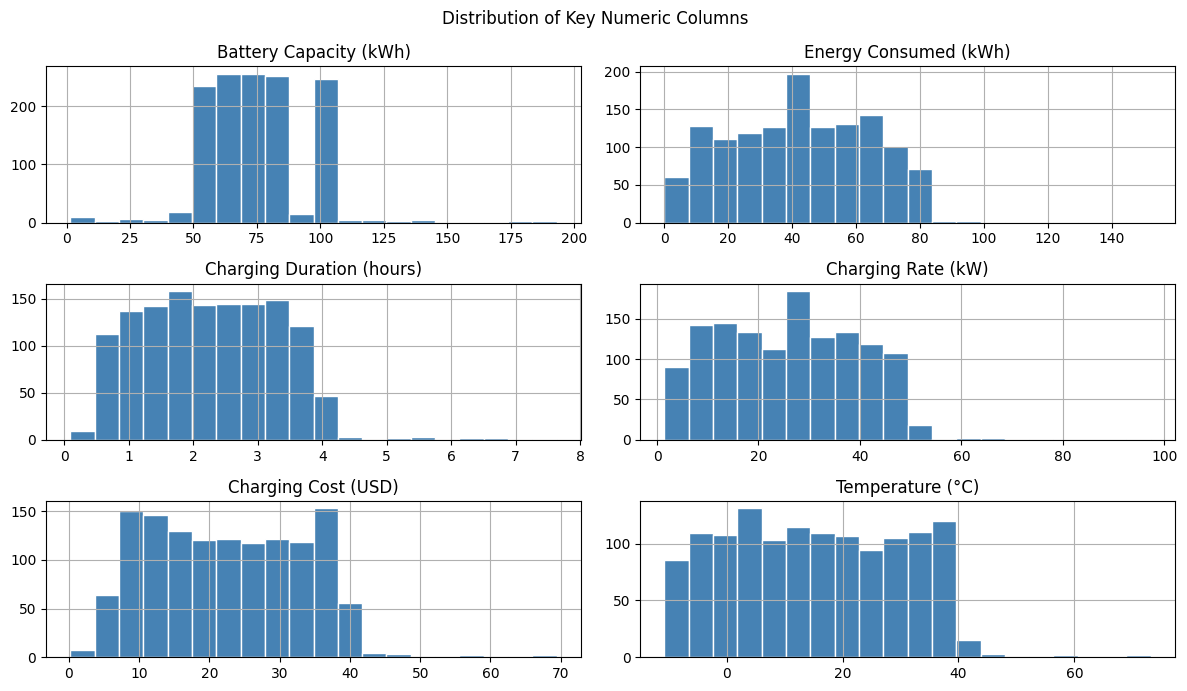

In [87]:
numeric_cols = ["Battery Capacity (kWh)", "Energy Consumed (kWh)", "Charging Duration (hours)",
                "Charging Rate (kW)", "Charging Cost (USD)", "Temperature (°C)"]

df[numeric_cols].hist(bins=20, figsize=(12, 7), color="steelblue", edgecolor="white")
plt.suptitle("Distribution of Key Numeric Columns")
plt.tight_layout()
plt.show()

**What to look for:** Check which values appear most often and whether any values look unusual. The charts will show the pattern in this dataset.

---
## Objective 1: Look at users, cars, and chargers

**Question:** Which vehicle models, user types, and charger types appear most often?

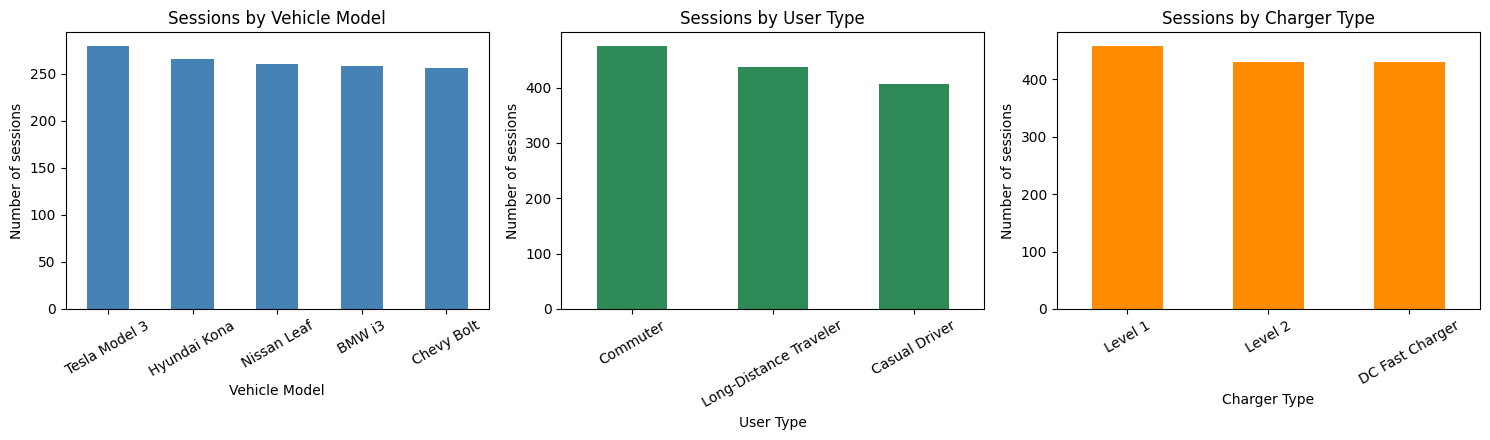

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

df["Vehicle Model"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Sessions by Vehicle Model")

df["User Type"].value_counts().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Sessions by User Type")

df["Charger Type"].value_counts().plot(kind="bar", ax=axes[2], color="darkorange")
axes[2].set_title("Sessions by Charger Type")

for ax in axes:
    ax.set_ylabel("Number of sessions")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [89]:
# Percentage share of each user type
(df["User Type"].value_counts(normalize=True) * 100).round(1)

User Type
Commuter                  36.1
Long-Distance Traveler    33.1
Casual Driver             30.8
Name: proportion, dtype: float64

This table counts the number of sessions for each user type and charger type.

In [90]:
pd.crosstab(df["User Type"], df["Charger Type"])

Charger Type,DC Fast Charger,Level 1,Level 2
User Type,,,
Casual Driver,138,141,128
Commuter,142,160,174
Long-Distance Traveler,150,158,129


**What the results tell us:** Use the charts and tables above to see which groups are most common. Small differences do not necessarily mean that one group is very different from the others.

---
## Objective 2: Compare charging cost by city and charger type

**Question:** Which locations and charger types have the highest average charging cost?

Charging Station Location
Chicago          23.72
Los Angeles      22.54
New York         22.50
Houston          22.09
San Francisco    21.99
Name: Charging Cost (USD), dtype: float64


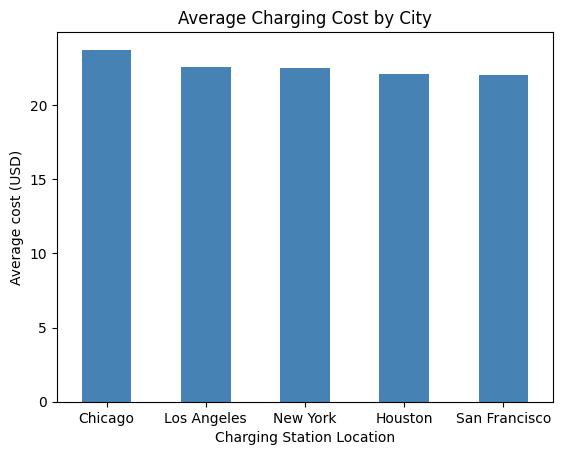

In [91]:
cost_by_city = df.groupby("Charging Station Location")["Charging Cost (USD)"].mean().sort_values(ascending=False)
print(cost_by_city.round(2))

cost_by_city.plot(kind="bar", color="steelblue")
plt.title("Average Charging Cost by City")
plt.ylabel("Average cost (USD)")
plt.xticks(rotation=0)
plt.show()

In [92]:
charger_summary = df.groupby("Charger Type")[["Charging Cost (USD)", "Energy Consumed (kWh)", "Charging Duration (hours)"]].mean()
charger_summary.round(2)

,Charging Cost (USD),Energy Consumed (kWh),Charging Duration (hours)
Charger Type,,,
DC Fast Charger,23.60,41.37,2.28
Level 1,21.66,41.66,2.24
Level 2,22.45,44.97,2.28


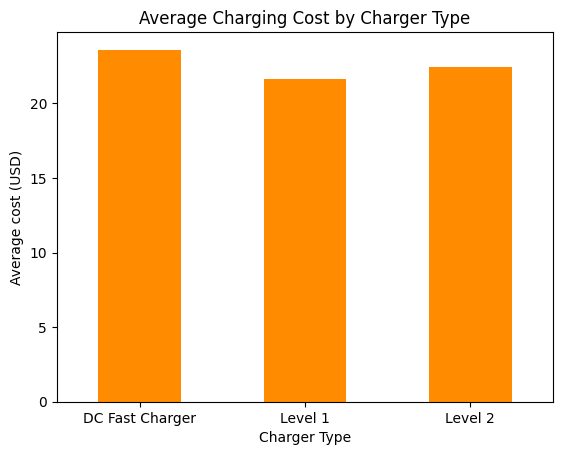

In [93]:
charger_summary["Charging Cost (USD)"].plot(kind="bar", color="darkorange")
plt.title("Average Charging Cost by Charger Type")
plt.ylabel("Average cost (USD)")
plt.xticks(rotation=0)
plt.show()

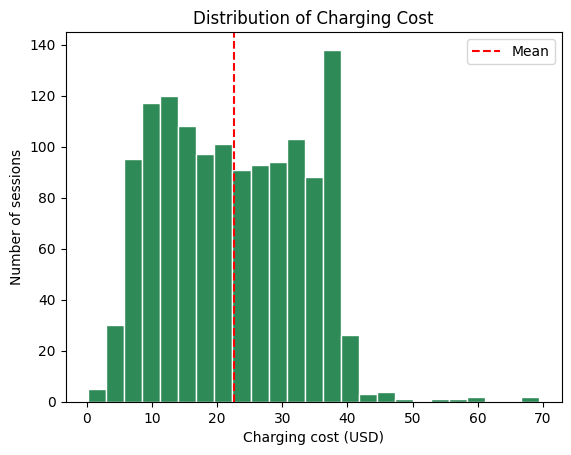

In [94]:
plt.hist(df["Charging Cost (USD)"], bins=25, color="seagreen", edgecolor="white")
plt.axvline(df["Charging Cost (USD)"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Distribution of Charging Cost")
plt.xlabel("Charging cost (USD)")
plt.ylabel("Number of sessions")
plt.legend()
plt.show()

**What the results tell us:** Compare the averages shown above. The differences in this dataset are fairly small. These results describe this dataset only and may not match real charging prices.

---
## Objective 3: Look at charging times

**Question:** At what times and on which days do people charge? Is the average cost different on weekends?

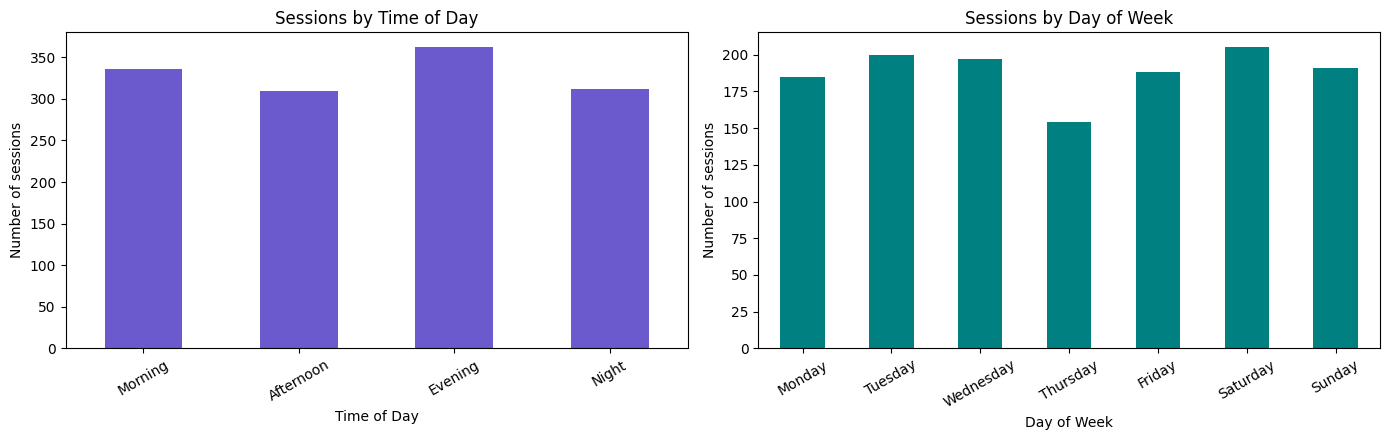

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

time_order = ["Morning", "Afternoon", "Evening", "Night"]
df["Time of Day"].value_counts().reindex(time_order).plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("Sessions by Time of Day")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["Day of Week"].value_counts().reindex(day_order).plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Sessions by Day of Week")

for ax in axes:
    ax.set_ylabel("Number of sessions")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [96]:
weekend_summary = df.groupby("Is Weekend")[["Charging Cost (USD)", "Energy Consumed (kWh)", "Charging Duration (hours)"]].mean()
weekend_summary.index = ["Weekday", "Weekend"]
weekend_summary.round(2)

,Charging Cost (USD),Energy Consumed (kWh),Charging Duration (hours)
Weekday,22.83,42.67,2.31
Weekend,21.89,42.59,2.16


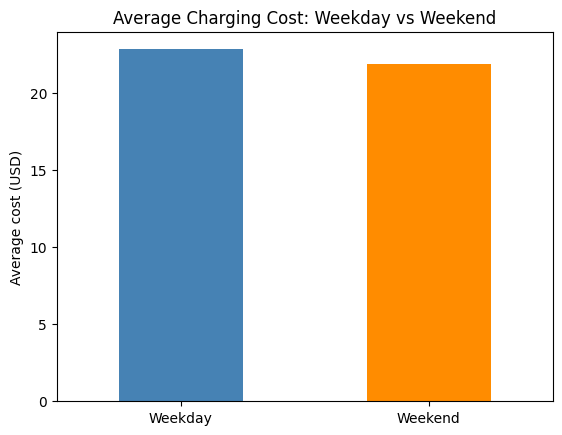

In [97]:
weekend_summary["Charging Cost (USD)"].plot(kind="bar", color=["steelblue", "darkorange"])
plt.title("Average Charging Cost: Weekday vs Weekend")
plt.ylabel("Average cost (USD)")
plt.xticks(rotation=0)
plt.show()

**What the results tell us:** Check the charts to find the busiest time and day. The table compares average cost, energy use, and charging duration on weekdays and weekends.

---
## Objective 4: Check relationships between number-based columns

**Question:** Do values such as energy use, charging time, and charging cost change together?

Correlation is a number between -1 and +1:
- Close to **+1** means the two values tend to increase together.
- Close to **-1** means one tends to decrease when the other increases.
- Close to **0** means there is little or no clear relationship.

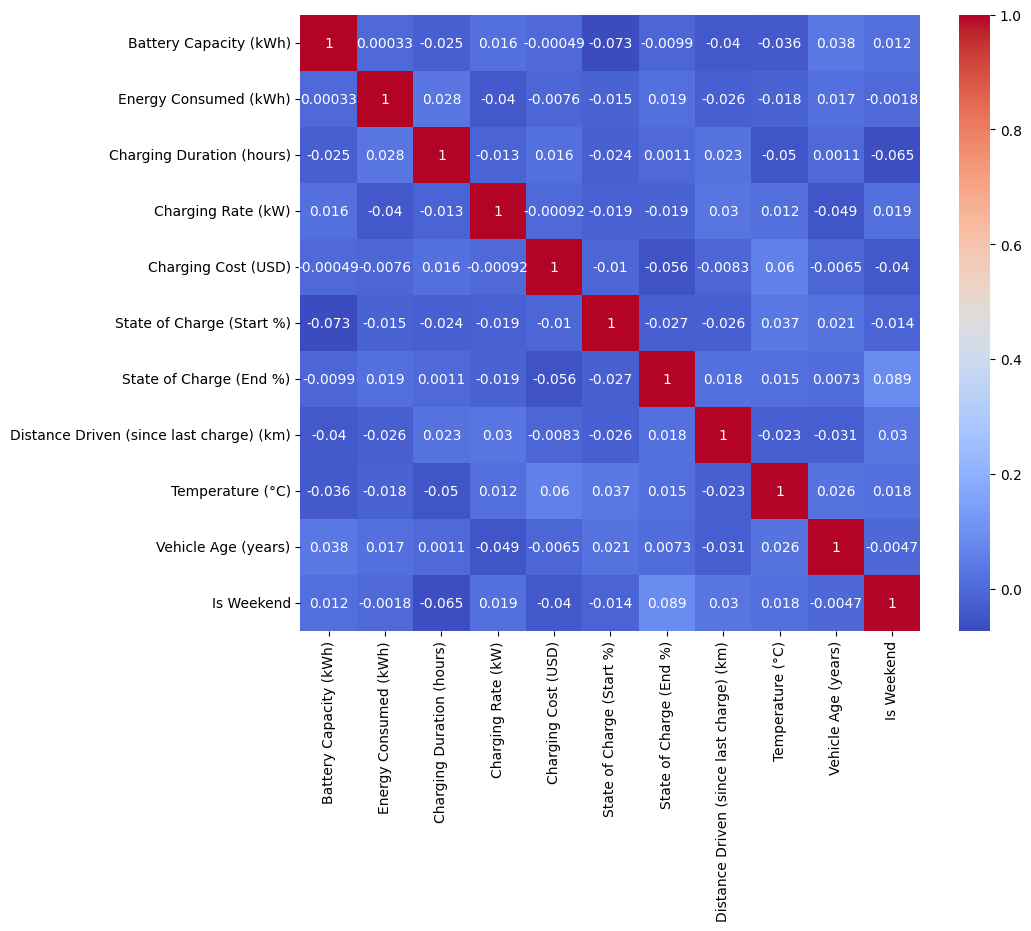

In [98]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")
plt.show()

In [114]:
# Which column is most related to Charging Cost?
corr["Charging Cost (USD)"].drop("Charging Cost (USD)").sort_values(key=abs, ascending=False).round(3)

Temperature (°C)                            0.064
State of Charge (End %)                    -0.052
Charging Duration (hours)                   0.016
Energy Consumed (kWh)                      -0.010
State of Charge (Start %)                  -0.009
Vehicle Age (years)                        -0.007
Distance Driven (since last charge) (km)   -0.003
Charging Rate (kW)                          0.001
Battery Capacity (kWh)                     -0.000
Name: Charging Cost (USD), dtype: float64

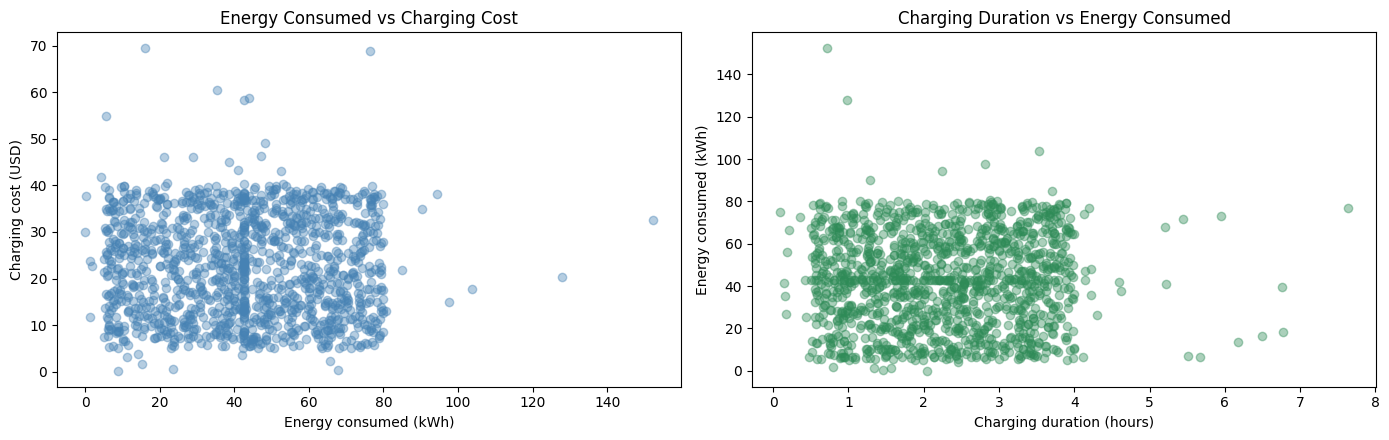

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(df["Energy Consumed (kWh)"], df["Charging Cost (USD)"], alpha=0.4, color="steelblue")
axes[0].set_xlabel("Energy consumed (kWh)")
axes[0].set_ylabel("Charging cost (USD)")
axes[0].set_title("Energy Consumed vs Charging Cost")

axes[1].scatter(df["Charging Duration (hours)"], df["Energy Consumed (kWh)"], alpha=0.4, color="seagreen")
axes[1].set_xlabel("Charging duration (hours)")
axes[1].set_ylabel("Energy consumed (kWh)")
axes[1].set_title("Charging Duration vs Energy Consumed")

plt.tight_layout()
plt.show()

**What the results tell us:** Look at the heatmap and scatter plots. If the points do not show a clear pattern and the correlations are close to zero, these columns do not have a strong relationship in this dataset. The data may be randomly generated, so we should be careful about drawing real-world conclusions.

---
## Objective 5: Try machine learning to predict charging cost

**Question:** Can we use the other columns to predict the cost of a charging session?

Because cost is a number, this is called a **regression** problem.

### 5.1 Choose the inputs and answer

- `X` contains the columns the model will use.
- `y` contains the charging cost we want to predict.

Computers need numbers, so `get_dummies()` changes text categories into number columns.

In [101]:
X = df.drop(columns=["Charging Cost (USD)"])
y = df["Charging Cost (USD)"]

X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Number of input features:", X.shape[1])
X.head()

Number of input features: 31


,Battery Capacity (kWh),Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Is Weekend,...,Day of Week_Monday,Day of Week_Saturday,Day of Week_Sunday,Day of Week_Thursday,Day of Week_Tuesday,Day of Week_Wednesday,Charger Type_Level 1,Charger Type_Level 2,User Type_Commuter,User Type_Long-Distance Traveler
0,108.463007,60.712346,0.591363,36.389181,29.371576,86.119962,293.602111,27.947953,2.0,0,...,0,0,0,0,1,0,0,0,1,0
1,100.000000,12.339275,3.133652,30.677735,10.115778,84.664344,112.112804,14.311026,3.0,0,...,1,0,0,0,0,0,1,0,0,0
2,75.000000,19.128876,2.452653,27.513593,6.854604,69.917615,71.799253,21.002002,2.0,0,...,0,0,0,1,0,0,0,1,1,0
3,50.000000,79.457824,1.266431,32.882870,83.120003,99.624328,199.577785,38.316313,1.0,1,...,0,1,0,0,0,0,1,0,0,1
4,50.000000,19.629104,2.019765,10.215712,54.258950,63.743786,203.661847,-7.834199,1.0,1,...,0,1,0,0,0,0,1,0,0,1


### 5.2 Split the data

We use 80% of the rows to train the models and keep 20% for testing. The test data helps us check how well the models work on rows they have not seen before.

In [102]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 1056
Testing rows : 264


### 5.3 Prepare the data for KNN

KNN compares how close rows are to each other. Scaling puts the input columns on a similar scale so columns with larger numbers do not dominate the comparison.

In [116]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 5.4 Check how well the models work

We will compare the models using three scores:

| Score | Simple meaning | Better result |
|---|---|---|
| **MAE** | Average prediction error in dollars | Lower |
| **RMSE** | Error score that gives bigger mistakes more weight | Lower |
| **R²** | How well the model explains changes in cost | Higher |

We also try a simple baseline: always predict the average cost from the training data. A useful model should do better than this simple guess.

In [117]:
# This function calculates the scores for each model.
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(name, "| MAE:", round(mae, 2),
          "| RMSE:", round(rmse, 2),
          "| R2:", round(r2, 3))

    return {"Model": name, "MAE": round(mae, 2),
            "RMSE": round(rmse, 2), "R2": round(r2, 3)}

results = []

# First, compare against a simple guess: the average training cost.
baseline_pred = np.full(len(y_test), y_train.mean())
results.append(evaluate("Baseline (average)", y_test, baseline_pred))

Baseline (average) | MAE: 9.44 | RMSE: 11.2 | R2: -0.0


### 5.5 Model 1: Linear Regression

This model tries to find a simple mathematical relationship between the inputs and the charging cost. It is a good starting point.

In [119]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
results.append(evaluate("Linear Regression", y_test, lr_pred))

Linear Regression | MAE: 9.39 | RMSE: 11.16 | R2: 0.007


### 5.6 Model 2: Decision Tree

A decision tree makes a series of simple splits in the data to make a prediction. We limit its depth to reduce the chance of memorising the training data.

In [106]:
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
results.append(evaluate("Decision Tree", y_test, dt_pred))

Decision Tree | MAE: 9.55 | RMSE: 11.38 | R2: -0.033


### 5.7 Model 3: K-Nearest Neighbors (KNN)

KNN looks for the five most similar sessions in the training data and uses their average cost to make a prediction.

In [107]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
results.append(evaluate("KNN (k=5)", y_test, knn_pred))

KNN (k=5) | MAE: 10.0 | RMSE: 11.94 | R2: -0.138


### 5.8 Model 4: Random Forest

Random Forest combines many decision trees and averages their predictions. This can be more stable than using just one tree.

In [120]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
results.append(evaluate("Random Forest", y_test, rf_pred))

Random Forest | MAE: 9.6 | RMSE: 11.37 | R2: -0.031


### 5.9 Compare the models

The table shows the scores for the baseline and the four machine learning models.

In [109]:
results_df = pd.DataFrame(results)
results_df

,Model,MAE,RMSE,R2
0,Baseline (average),9.44,11.20,-0.000
1,Linear Regression,9.39,11.16,0.007
2,Decision Tree,9.55,11.38,-0.033
3,KNN (k=5),10.00,11.94,-0.138
4,Random Forest,9.60,11.37,-0.031


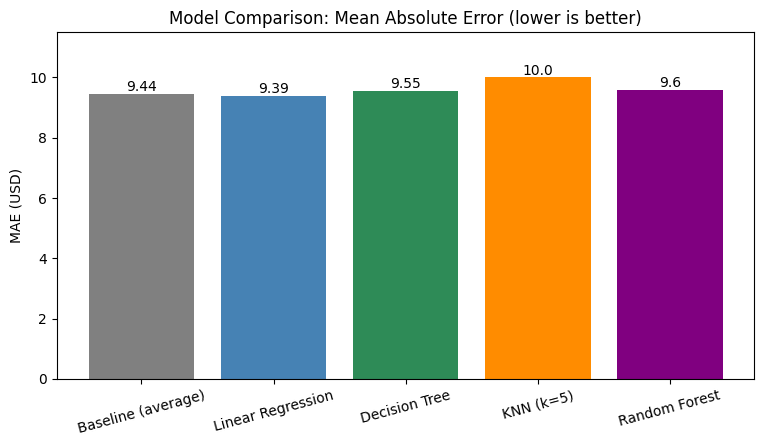

In [110]:
plt.figure(figsize=(9, 4.5))
colors = ["grey", "steelblue", "seagreen", "darkorange", "purple"]
plt.bar(results_df["Model"], results_df["MAE"], color=colors)
plt.title("Model Comparison: Mean Absolute Error (lower is better)")
plt.ylabel("MAE (USD)")
plt.xticks(rotation=15)
for i, v in enumerate(results_df["MAE"]):
    plt.text(i, v + 0.1, str(v), ha="center")
plt.ylim(0, results_df["MAE"].max() + 1.5)
plt.show()

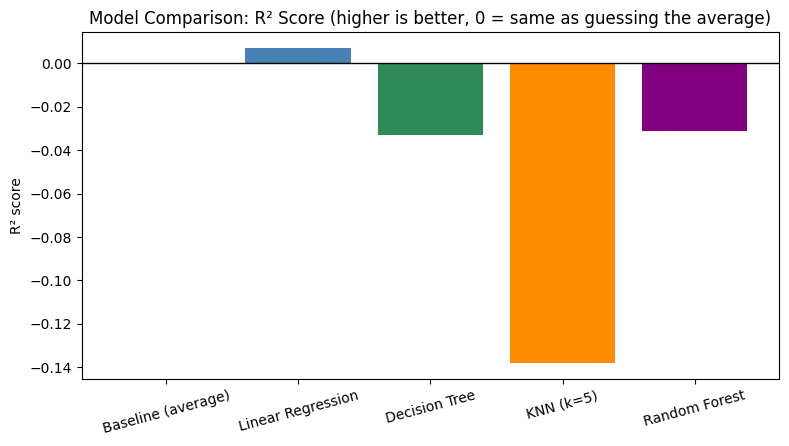

In [111]:
plt.figure(figsize=(9, 4.5))
plt.bar(results_df["Model"], results_df["R2"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.title("Model Comparison: R² Score (higher is better, 0 = same as guessing the average)")
plt.ylabel("R² score")
plt.xticks(rotation=15)
plt.show()

### 5.10 Compare actual and predicted costs

If the predictions were perfect, the dots would sit on the red dashed line. The farther they are from the line, the larger the prediction error.

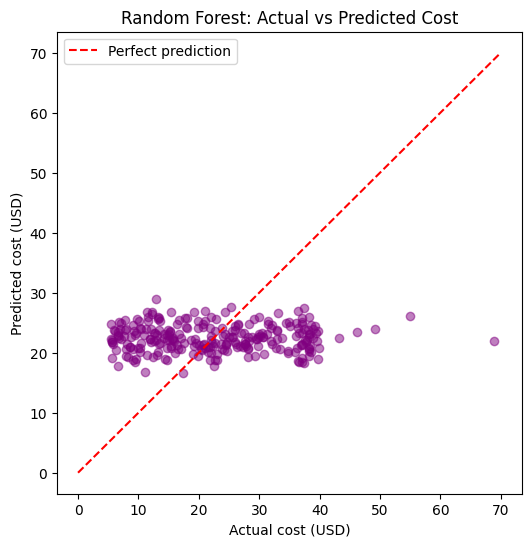

In [112]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, rf_pred, alpha=0.5, color="purple")
plt.plot([0, 70], [0, 70], "r--", label="Perfect prediction")
plt.xlabel("Actual cost (USD)")
plt.ylabel("Predicted cost (USD)")
plt.title("Random Forest: Actual vs Predicted Cost")
plt.legend()
plt.show()

### 5.11 Which columns mattered most to the Random Forest?

This chart shows which columns the Random Forest used most when making its decisions. These values do not prove that a column causes charging cost to change.

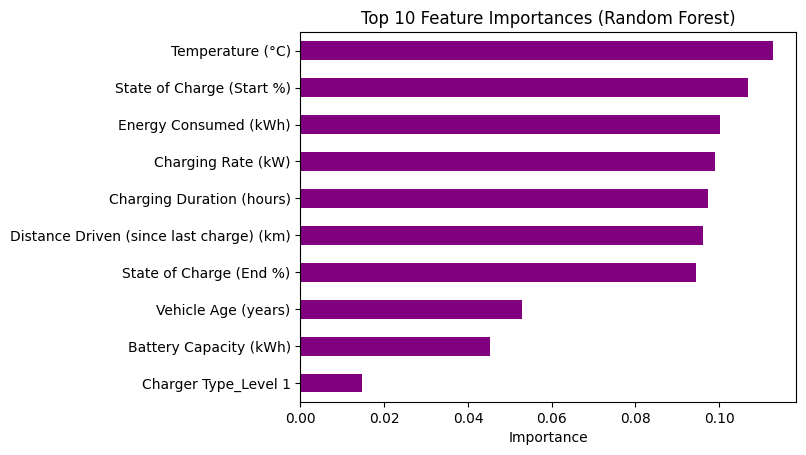

In [113]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

importance.sort_values().plot(kind="barh", color="purple")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.show()

### 5.12 What do the results mean?

Compare the machine learning models with the simple baseline.

If the models do not perform better than the baseline, it means the available columns may not contain enough useful information to predict charging cost. A model cannot learn a reliable pattern if the data does not contain one.

Feature importance charts should also be treated carefully when a model's predictions are poor.

---
## Conclusion

Use the charts, tables, and model scores above to write what you found.

In your own words, mention:
1. The most common vehicle, user type, and charger type.
2. Any differences in average cost between cities and charger types.
3. The busiest charging time or day, and any weekday/weekend difference.
4. Whether the number-based columns have clear relationships.
5. Which model performed best and whether it did better than the simple baseline.

**A point to remember:** These results describe only the dataset used in this notebook. Real charging data may show different patterns. To improve cost prediction, we would need reliable real-world prices and charging information.